# Data Understanding - Manu

**Equipo PINU · Fase 2 de CRISP-DM**

**Objetivo de negocio:** identificar problemas de cola mediante la detección de anomalías en el ordeñamiento.
**Objetivo de minería de datos:** clasificar los posibles tipos de evento que se presentan en el ordeño.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# Colores fijos para todas las graficas
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e5e1",
    "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 110,
})

In [2]:
# Busca la raiz del repo (la carpeta que contiene Data) sin importar desde donde se ejecute
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").exists())

# id_vaca y misc_eo_po son identificadores (hash), no cantidades: se leen como texto
df = pd.read_csv(raiz / "Data" / "dataset_vacas_anonimo.csv", dtype={"id_vaca": str, "misc_eo_po": str})
print(f"Registros: {df.shape[0]:,} | Columnas: {df.shape[1]}")

Registros: 7,249 | Columnas: 36


## 1. Visualizar y consultar los datos

Cada instancia es una visita de una vaca. Las columnas vienen en grupos: `main_*` (resumen de la sesión), `estado_*` (eventos ocurridos), mediciones por cuarto de la ubre y `misc_*`.

In [3]:
df.head()

,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td
0,3d995085,01/03/2025 05:37 a. m.,Ordeño,09:58,23.96,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.26,1.74,1.86,1.62,0.0,0.0,0.0,0.0,4.92,5.16,5.48,5.21,7063e4b1,NaN,Tanque,NaN,1.74,2.16,2.40,2.10,6.11,5.56,3.33,8.96
1,3d995085,01/03/2025 07:15 p. m.,Ordeño,06:51,17.20,2.0,NaN,DI,NaN,NaN,1.0,NaN,1.14,1.80,2.04,1.74,0.0,0.0,0.0,0.0,4.58,4.84,5.26,4.88,7063e4b1,NaN,Tanque,NaN,2.10,2.34,2.52,2.28,3.23,4.86,2.69,6.42
2,3d995085,02/03/2025 02:24 a. m.,Ordeño,07:23,11.13,1.0,NaN,NaN,NaN,NaN,1.0,TI,1.20,1.44,1.74,1.44,0.0,0.0,0.0,0.0,4.26,4.38,5.00,4.52,7063e4b1,NaN,Tanque,NaN,1.68,1.98,2.34,1.92,4.40,2.43,1.15,3.15
3,3d995085,02/03/2025 07:51 p. m.,Ordeño,08:29,20.64,2.0,NaN,NaN,NaN,NaN,1.0,NaN,1.20,1.68,1.92,1.68,0.0,0.0,0.0,0.0,4.36,4.77,5.01,4.82,7063e4b1,NaN,Tanque,NaN,2.10,2.22,2.52,2.40,5.72,4.88,3.10,6.94
4,3d995085,03/03/2025 06:00 a. m.,Ordeño,05:05,9.59,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.14,1.62,1.80,1.50,0.0,0.0,0.0,0.0,4.13,4.42,4.36,4.44,7063e4b1,NaN,Tanque,NaN,1.80,2.10,2.28,1.98,2.69,2.41,1.44,3.05


In [4]:
# Consulta: que tipo de visitas hay y en que robot ocurren
pd.crosstab(df["main_accion"], df["misc_eo_po"], margins=True, margins_name="Total")

misc_eo_po,7063e4b1,86696b37,b96e85be,Total
main_accion,,,,
Echada sin ordeñar,42,11,8,61
Ordeño,4134,1615,1267,7016
Rechazada,100,48,24,172
Total,4276,1674,1299,7249


In [5]:
# Consulta: cuantos registros tiene cada vaca
registros_vaca = df.groupby("id_vaca").size().sort_values()
print(f"Vacas: {registros_vaca.size} | min: {registros_vaca.min()} | mediana: {registros_vaca.median():.0f} | max: {registros_vaca.max()}")
print("\nVacas con menos de 30 registros:")
print(registros_vaca[registros_vaca < 30].to_string())

Vacas: 34 | min: 2 | mediana: 248 | max: 421

Vacas con menos de 30 registros:
id_vaca
ed537d8a     2
8c740a5e     8
48978300    10


In [6]:
# Consulta: ejemplo de sesiones con ordeño incompleto
columnas_consulta = ["id_vaca", "main_hora_de_inicio", "main_duracion_mm_ss", "main_produccion_kg",
                     "estado_patada", "estado_incompleto", "estado_pezones_no_encontrados", "misc_eo_po"]
df[df["estado_incompleto"].notna()][columnas_consulta].head(8)

,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,estado_patada,estado_incompleto,estado_pezones_no_encontrados,misc_eo_po
40,3d995085,25/03/2025 12:35 p. m.,04:23,3.40,NaN,Todos,NaN,7063e4b1
49,3d995085,30/03/2025 02:36 p. m.,04:44,5.74,NaN,Todos,NaN,7063e4b1
76,3d995085,16/04/2025 08:21 p. m.,03:27,1.05,NaN,Todos,"DI,DD,TI",7063e4b1
86,3d995085,23/04/2025 10:25 p. m.,10:50,21.58,NaN,TI,TI,7063e4b1
88,3d995085,25/04/2025 12:24 p. m.,07:49,12.94,NaN,TI,NaN,7063e4b1
98,3d995085,30/04/2025 11:32 p. m.,11:08,18.78,NaN,TI,TI,7063e4b1
100,3d995085,02/05/2025 03:43 a. m.,07:21,13.61,NaN,TI,NaN,7063e4b1
101,3d995085,02/05/2025 09:54 p. m.,09:18,19.38,NaN,TI,TI,7063e4b1


In [7]:
# Estadisticos descriptivos de las variables numericas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
main_produccion_kg,7016.0,13.72,5.33,0.0,9.86,13.26,17.06,39.47
estado_numero_de_ordeno,7016.0,1.77,0.81,1.0,1.00,2.00,2.00,5.00
estado_rcs_1000_celulas_ml,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_amd_ubre,7016.0,0.15,0.36,0.0,0.00,0.00,0.00,1.00
media_de_los_flujos_kg_min_di,7016.0,1.03,0.43,0.0,0.78,1.02,1.32,4.98
media_de_los_flujos_kg_min_dd,7013.0,1.11,0.40,0.0,0.84,1.08,1.38,2.64
media_de_los_flujos_kg_min_ti,6717.0,1.05,0.49,0.0,0.78,1.08,1.32,4.08
media_de_los_flujos_kg_min_td,6952.0,1.07,0.45,0.0,0.84,1.08,1.32,2.82
sangre_ppm_di,7016.0,23.16,287.06,0.0,0.00,0.00,0.00,7997.00
sangre_ppm_dd,7013.0,8.60,89.22,0.0,0.00,0.00,0.00,2786.00


**Observaciones**

- Hay tres tipos de visita: `Ordeño`, `Rechazada` (la vaca entra pero el robot no la ordeña) y `Echada sin ordeñar`. Solo las de `Ordeño` tienen mediciones.
- El historial por vaca es muy desigual: 3 vacas (`ed537d8a`, `8c740a5e`, `48978300`) tienen 10 registros o menos, porque aparecen hasta la última semana del periodo.
- `sangre_ppm_*` es casi siempre 0 con máximos cercanos a 8,000: distribución muy sesgada.
- `conductividad_ms_cm_*` tiene mínimo 0, valor físicamente imposible para leche; se revisa en la sección de nulos.
- Se tiene medida la hora de inicio y la duración del ordeño, más no se tiene datos sobre la hora de salida.

### Descripción de cada columna:

Cada fila es una visita de una vaca a una máquina de ordeño. Los sufijos `_di`, `_dd`, `_ti` y `_td` indican el cuarto de la ubre: delantero izquierdo, delantero derecho, trasero izquierdo y trasero derecho.

**Identificación y resumen de la sesión**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `id_vaca` | Identificador de la vaca, anonimizado con un hash. | Identificador |
| `main_hora_de_inicio` | Fecha y hora en que inició la visita (`dd/mm/aaaa hh:mm a. m./p. m.`), con precisión de minutos. | Fecha y hora (texto) |
| `main_accion` | Resultado de la visita: `Ordeño`, `Rechazada` (la vaca entró pero no fue ordeñada) o `Echada sin ordeñar`. | Categórica |
| `main_duracion_mm_ss` | Duración de la visita en minutos y segundos. | Duración (texto) |
| `main_produccion_kg` | Leche total obtenida en el ordeño, en kg. Es la suma de los cuatro cuartos. | Numérica continua |

**Estado y eventos del ordeño**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `estado_numero_de_ordeno` | Número consecutivo del ordeño de la vaca en el día (1 a 5). | Numérica discreta |
| `estado_rcs_1000_celulas_ml` | Recuento de células somáticas, en miles de células por ml. Indicador de salud de la ubre. **Vacía en todos los registros.** | Numérica (sin datos) |
| `estado_patada` | Cuartos en los que la vaca pateó la pezonera. Vacío = no hubo patada. | Evento por cuarto |
| `estado_incompleto` | Cuartos cuyo ordeño no se completó. Vacío = ordeño completo. | Evento por cuarto |
| `estado_pezones_no_encontrados` | Cuartos en los que la máquina no logró localizar el pezón. Vacío = se encontraron todos. | Evento por cuarto |
| `estado_amd_ubre` | Alerta AMD a nivel de ubre (0 = sin alerta, 1 = con alerta). *Significado de AMD por confirmar.* | Binaria |
| `estado_amd_pezon` | Cuartos con alerta AMD. Vacío = sin alerta. *Significado de AMD por confirmar.* | Evento por cuarto |

En las columnas de evento por cuarto el valor es la lista de cuartos afectados (`TI`, `DI,TD`) o `Todos`.

**Mediciones por cuarto** (cuatro columnas cada una: `_di`, `_dd`, `_ti`, `_td`)

| Columnas | Descripción | Tipo |
| :-- | :-- | :-- |
| `media_de_los_flujos_kg_min_*` | Flujo promedio de leche del cuarto durante el ordeño, en kg/min. | Numérica continua |
| `flujos_maximos_kg_min_*` | Flujo máximo de leche alcanzado en el cuarto, en kg/min. | Numérica continua |
| `producciones_kg_*` | Leche obtenida del cuarto, en kg. | Numérica continua |
| `sangre_ppm_*` | Sangre detectada en la leche del cuarto, en partes por millón. Normalmente es 0. | Numérica continua |
| `conductividad_ms_cm_*` | Conductividad eléctrica de la leche del cuarto, en mS/cm. Valores altos se asocian con mastitis. Un 0 se interpreta como lectura faltante. | Numérica continua |

**Otros**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `misc_eo_po` | Máquina de ordeño en la que ocurrió la visita, anonimizada con un hash (3 máquinas). | Categórica |
| `misc_usuario` | Usuario que intervino en la sesión. **Vacía en todos los registros.** | Sin datos |
| `misc_destino_leche` | A dónde se envió la leche: `Tanque`, `Drenaje` (se desecha) o `Divert 3` (se desvía a una línea aparte). | Categórica |
| `misc_razon_de_la_desviacion` | Motivo por el que la leche no fue al tanque. Solo tiene un valor en todo el dataset. | Categórica (casi sin datos) |

## 2. Tipos de datos

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7249 entries, 0 to 7248
Data columns (total 36 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_vaca                        7249 non-null   str    
 1   main_hora_de_inicio            7249 non-null   str    
 2   main_accion                    7249 non-null   str    
 3   main_duracion_mm_ss            7249 non-null   str    
 4   main_produccion_kg             7016 non-null   float64
 5   estado_numero_de_ordeno        7016 non-null   float64
 6   estado_rcs_1000_celulas_ml     0 non-null      float64
 7   estado_patada                  1299 non-null   str    
 8   estado_incompleto              1014 non-null   str    
 9   estado_pezones_no_encontrados  1239 non-null   str    
 10  estado_amd_ubre                7016 non-null   float64
 11  estado_amd_pezon               802 non-null    str    
 12  media_de_los_flujos_kg_min_di  7016 non-null   float64
 13 

**Observaciones**

- El tipo que asigna pandas no coincide con el tipo real en varias columnas: la fecha, la hora de inicio y la duración están como texto, y `estado_numero_de_ordeno` / `estado_amd_ubre` aparecen como `float` solo porque tienen nulos.
- Las cuatro columnas de evento (`patada`, `incompleto`, `pezones_no_encontrados`, `amd_pezon`) no guardan sí/no, sino **la lista de cuartos afectados** (`TI`, `DI,TD`, `Todos`). Hay que convertirlas en variables utilizables.
- 21 columnas son mediciones continuas: la producción total más 5 magnitudes × 4 cuartos.

## 3. Nulos: cantidad y porcentaje

In [9]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)

print(f"Celdas nulas: {df.isna().sum().sum():,} de {df.size:,} ({df.isna().sum().sum() / df.size:.1%})")
nulos

Celdas nulas: 53,810 de 260,964 (20.6%)


,nulos,porcentaje
estado_rcs_1000_celulas_ml,7249,100.00
misc_usuario,7249,100.00
misc_razon_de_la_desviacion,7248,99.99
estado_amd_pezon,6447,88.94
estado_incompleto,6235,86.01
estado_pezones_no_encontrados,6010,82.91
estado_patada,5950,82.08
sangre_ppm_ti,532,7.34
producciones_kg_ti,532,7.34
flujos_maximos_kg_min_ti,532,7.34


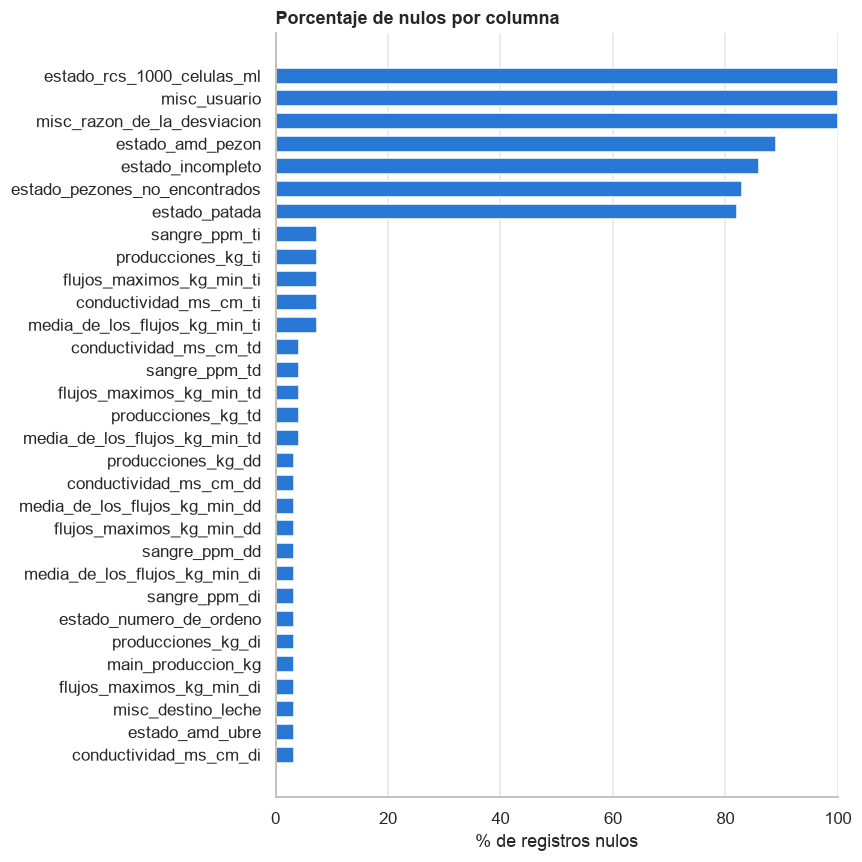

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
orden = nulos[nulos["nulos"] > 0].sort_values("porcentaje")
ax.barh(orden.index, orden["porcentaje"], color=AZUL, height=0.7)
ax.set_title("Porcentaje de nulos por columna")
ax.set_xlabel("% de registros nulos")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

El porcentaje por sí solo engaña: casi ningún nulo es un dato "perdido". Se revisa de dónde viene cada bloque.

In [11]:
# Bloque de 3.21 %: los nulos de las mediciones dependen del tipo de visita?
pd.crosstab(df["main_accion"], df["main_produccion_kg"].isna().map({True: "produccion nula", False: "con produccion"}))

main_produccion_kg,con produccion,produccion nula
main_accion,,
Echada sin ordeñar,0,61
Ordeño,7016,0
Rechazada,0,172


**Observaciones:**
 - En ordeño no se tienen ningun dato nulo de producción total.
 - Cuando es rechazada y echada sin ordeñar no se obtienen datos de producción lo cual es normal y es lo esperado.

In [12]:
# Nulos en los cuartos traseros: estan repartidos o concentrados en vacas especificas?
ordenos = df[df["main_accion"] == "Ordeño"]
for cuarto in ["dd", "ti", "td", "di"]:
    faltantes = ordenos[ordenos[f"producciones_kg_{cuarto}"].isna()]["id_vaca"].value_counts()
    print(f"Cuarto {cuarto.upper()} sin medicion en {faltantes.sum()} ordeños -> vacas: {faltantes.to_dict()}")

Cuarto DD sin medicion en 3 ordeños -> vacas: {'cbcd0724': 3}
Cuarto TI sin medicion en 299 ordeños -> vacas: {'7648b6a6': 299}
Cuarto TD sin medicion en 64 ordeños -> vacas: {'505279da': 64}
Cuarto DI sin medicion en 0 ordeños -> vacas: {}


**Observaciones:**
- En los ordeños, el cuarto DI nunca tiene mediciones nulas.
- Los nulos de los otros cuartos no están repartidos en el total: en cada cuarto vienen de una sola vaca.
- La vaca `7648b6a6` no tiene medición del cuarto TI en ninguno de sus 299 ordeños, y la vaca `505279da` tampoco del cuarto TD en ninguno de sus 64. Lo más probable es que ese cuarto no se ordeñe; queda por confirmar con el socio formador.
- La vaca `cbcd0724` solo tiene 3 ordeños sin medición en DD, de 298: es algo esporádico, no un cuarto inactivo.
- Estos nulos no se deben imputar, porque esa leche nunca existió. Además, el modelo debe saber cuántos cuartos se ordeñan en cada vaca: una vaca de tres cuartos produce menos y eso es normal, no una anomalía.


In [13]:
# Nulos "escondidos": la conductividad de la leche no puede ser 0
# Para cada cuarto: cuantos ceros hay y con que coinciden en ese mismo cuarto
filas = []
for cuarto in ["di", "dd", "ti", "td"]:
    es_cero = ordenos[f"conductividad_ms_cm_{cuarto}"] == 0
    sin_leche = ordenos[f"producciones_kg_{cuarto}"] == 0
    incompleto = ordenos["estado_incompleto"].fillna("").str.contains(cuarto.upper()) | (ordenos["estado_incompleto"] == "Todos")
    filas.append({
        "cuarto": cuarto.upper(),
        "ceros": es_cero.sum(),
        "% de los ordeños": es_cero.mean() * 100,
        "% de los ceros con produccion 0 kg": sin_leche[es_cero].mean() * 100,
        "% de los ceros con cuarto incompleto": incompleto[es_cero].mean() * 100,
        "% incompleto cuando no es cero": incompleto[~es_cero].mean() * 100,
    })
ceros = pd.DataFrame(filas).set_index("cuarto").round(1)
ceros

,ceros,% de los ordeños,% de los ceros con produccion 0 kg,% de los ceros con cuarto incompleto,% incompleto cuando no es cero
cuarto,,,,,
DI,266,3.8,98.5,56.4,1.6
DD,141,2.0,73.8,70.9,0.8
TI,605,8.6,93.6,69.6,2.2
TD,1543,22.0,24.6,20.0,1.8


In [14]:
# Los ceros del cuarto TD se comportan distinto: de que maquina vienen?
cero_td = ordenos["conductividad_ms_cm_td"] == 0
por_maquina = pd.DataFrame({
    "ordeños": ordenos.groupby("misc_eo_po").size(),
    "ceros_td": cero_td.groupby(ordenos["misc_eo_po"]).sum(),
    "% de sus ordeños": (cero_td.groupby(ordenos["misc_eo_po"]).mean() * 100).round(1),
    "produccion_td_mediana_en_ceros": ordenos[cero_td].groupby("misc_eo_po")["producciones_kg_td"].median(),
})
print(por_maquina)

print(f"\nConductividad TD promedio con ceros: {ordenos['conductividad_ms_cm_td'].mean():.2f} | sin ceros: {ordenos.loc[~cero_td, 'conductividad_ms_cm_td'].mean():.2f}")
print(f"Ordeños con produccion total = 0 kg: {(ordenos['main_produccion_kg'] == 0).sum()}")

            ordeños  ceros_td  % de sus ordeños  produccion_td_mediana_en_ceros
misc_eo_po                                                                     
7063e4b1       4134       214               5.2                            0.00
86696b37       1615       113               7.0                            0.00
b96e85be       1267      1216              96.0                            3.61

Conductividad TD promedio con ceros: 3.82 | sin ceros: 4.91
Ordeños con produccion total = 0 kg: 4


**Observaciones:**
- La conductividad de la leche normalmente está entre 4 y 6 mS/cm, así que un 0 no es una medición real. Son datos faltantes que `.isna()` no detecta.
- Los ceros significan dos cosas distintas según el cuarto:
  - **En DI, DD y TI, el cuarto no dio leche.** Entre 74 % y 98 % de esos ceros coinciden con producción de 0 kg en el mismo cuarto, y entre 56 % y 71 % con el cuarto marcado como incompleto (contra 1–2 % cuando la conductividad no es 0).
  - **En TD, la mayoría viene de una sola máquina.** La máquina `b96e85be` tiene conductividad TD en 0 en 1,216 de sus 1,267 ordeños (96 %), aunque el cuarto sí produjo leche (mediana de 3.61 kg). Apunta a una falla del sensor de ese cuarto en esa máquina. En las otras dos máquinas los ceros de TD son pocos (5–7 %) y se comportan como en los demás cuartos: sin leche.
- Antes de usar la conductividad hay que convertir los ceros en faltantes: con ellos el promedio de TD es 3.82; sin ellos, 4.91.
- En DI, DD y TI el cero casi repite la etiqueta de ordeño incompleto. Usarlo como variable del modelo sería fuga de información.
- Hay 4 ordeños con producción total de 0 kg.

**Observaciones: hay cuatro tipos de nulo distintos**

| Tipo | Columnas | Qué significa | Tratamiento sugerido |
| :-- | :-- | :-- | :-- |
| Columna vacía (100 %) | `estado_rcs_1000_celulas_ml` | El recuento de células somáticas no se registra en ningún ordeño | Eliminar |
| Columna vacía (100 %) | `misc_usuario` | Usuario que intervino manualmente en la sesión; no hay ninguno registrado en todo el periodo | Eliminar |
| Casi vacía (99.99 %) | `misc_razon_de_la_desviacion` | Un solo valor en todo el dataset | Eliminar |
| Nulo = "no ocurrió" (82–89 %) | `estado_patada`, `estado_incompleto`, `estado_pezones_no_encontrados`, `estado_amd_pezon` | La celda vacía significa que el evento **no** pasó | Convertir a 0/1, no imputar |
| Nulo estructural (3.21 %) | Todas las mediciones | Son exactamente las 233 visitas que no fueron ordeño | Separar por tipo de visita |
| Cuarto no ordeñado | `*_ti`, `*_td`, `*_dd` | La vaca `7648b6a6` nunca tiene medición en TI y la `505279da` nunca en TD: probablemente cuartos que no se ordeñan | Confirmar con el socio formador |
| Cero como nulo | `conductividad_ms_cm_*` | En DI, DD y TI el 0 aparece cuando el cuarto no dio leche. En TD, 22 % de los ordeños tienen 0 y casi todos vienen de la máquina `b96e85be` (96 % de sus ordeños) | Tratar como faltante y confirmar con socio |

Solo los dos últimos son problemas de calidad reales. El resto es información, no ausencia de ella.

## 4. Datos duplicados

In [15]:
print(f"Filas duplicadas exactas:                    {df.duplicated().sum()}")
print(f"Misma vaca y misma hora de inicio:           {df.duplicated(['id_vaca', 'main_hora_de_inicio']).sum()}")
print(f"Fila identica en vacas distintas (sin id):   {df.drop(columns='id_vaca').duplicated().sum()}")

Filas duplicadas exactas:                    2
Misma vaca y misma hora de inicio:           25
Fila identica en vacas distintas (sin id):   5


In [16]:
# Duplicados exactos
df[df.duplicated(keep=False)][["id_vaca", "main_hora_de_inicio", "main_accion", "main_duracion_mm_ss", "misc_eo_po"]]

,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,misc_eo_po
1231,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,86696b37
1232,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,86696b37
6031,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,7063e4b1
6032,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,7063e4b1


In [17]:
# Misma vaca y misma hora: que combinaciones de accion forman cada par?
repetidos = df[df.duplicated(["id_vaca", "main_hora_de_inicio"], keep=False)]
pares = (repetidos.groupby(["id_vaca", "main_hora_de_inicio"])["main_accion"]
         .apply(lambda acciones: " + ".join(sorted(acciones))))
print(pares.value_counts().to_string())

print("\nFechas en las que ocurren los pares Ordeño + Echada sin ordeñar:")
print(pares[pares.str.contains("Echada")].index.get_level_values(1).str[:10].value_counts().to_string())

repetidos[["id_vaca", "main_hora_de_inicio", "main_accion", "main_duracion_mm_ss", "main_produccion_kg", "misc_eo_po"]].head(8)

main_accion
Echada sin ordeñar + Ordeño                         18
Rechazada + Rechazada                                2
Ordeño + Rechazada                                   2
Echada sin ordeñar + Echada sin ordeñar              1
Echada sin ordeñar + Echada sin ordeñar + Ordeño     1

Fechas en las que ocurren los pares Ordeño + Echada sin ordeñar:
main_hora_de_inicio
16/03/2025    11
27/06/2025     7
16/04/2025     1
06/06/2025     1


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,misc_eo_po
447,453b8961,27/06/2025 01:24 p. m.,Ordeño,07:31,13.94,7063e4b1
448,453b8961,27/06/2025 01:24 p. m.,Echada sin ordeñar,07:31,NaN,7063e4b1
793,505279da,16/07/2025 03:20 p. m.,Ordeño,00:55,0.00,7063e4b1
794,505279da,16/07/2025 03:20 p. m.,Rechazada,00:54,NaN,7063e4b1
795,505279da,16/07/2025 03:23 p. m.,Ordeño,09:55,1.23,7063e4b1
796,505279da,16/07/2025 03:23 p. m.,Rechazada,09:55,NaN,7063e4b1
832,0072065b,16/03/2025 05:03 a. m.,Ordeño,11:52,23.58,86696b37
833,0072065b,16/03/2025 05:03 a. m.,Echada sin ordeñar,11:51,NaN,86696b37


**Observaciones**

- Solo hay **2 duplicados exactos** (dos visitas `Rechazada` de duración 00:00). Se pueden eliminar sin pérdida.
- Hay **25 filas que repiten vaca y hora de inicio**, pero la mayoría no son copias: 19 son un `Ordeño` acompañado de un registro `Echada sin ordeñar` con la misma duración y sin producción. 18 de esos 19 casos caen en dos fechas (16/03/2025 y 27/06/2025), lo que apunta a un evento del sistema o del rancho esos días y no a un error de captura. **No se eliminan a ciegas**; hay que preguntar qué pasó en esas fechas.
- Las filas idénticas entre vacas distintas son solo visitas `Rechazada` de 00:00 en el mismo minuto: coincidencia, no duplicado.
- La llave natural de un registro es `id_vaca` + `hora_de_inicio` + `accion`.

## 5. Resumen de hallazgos y pendientes

**El dataset**

- 7,249 visitas de 34 vacas a 3 robots, del 1 de marzo al 18 de julio de 2025. 7,016 son ordeños.
- 36 columnas: 3 no aportan nada (`estado_rcs_1000_celulas_ml`, `misc_usuario`, `misc_razon_de_la_desviacion`).

**Calidad**

- Nulos: casi todos son estructurales (visita sin ordeño) o significan "no ocurrió". Los problemas reales son los ceros de conductividad y dos vacas con un cuarto sin medición.
- Duplicados: 2 exactos. Los pares `Ordeño` + `Echada sin ordeñar` del 16/03 y 27/06 necesitan explicación antes de decidir qué hacer.
- Tipos: fecha, duración y eventos requieren transformación antes de usarse.

**Preguntas para el socio formador**

- ¿Qué pasó el 16/03/2025 y el 27/06/2025 (registros `Echada sin ordeñar` pareados con un ordeño)?
- ¿Las vacas `7648b6a6` y `505279da` tienen un cuarto que no se ordeña?
- ¿El sensor de conductividad del cuarto TD de la máquina `b96e85be` está fallando? Registra 0 en 96 % de sus ordeños.
- ¿Qué significan exactamente `AMD ubre` y `AMD pezón`, y `Divert 3` como destino de la leche?